


1.   Se carga modelo 1
2.   A modelo se saca 1 layer
3.   Se cargan modelos 2(solo chile continental)
4.   se cargan los datos de la casen usando las mismas variables del censo
5.   se hace una regresion del ingreso casen con respecto a las variables $F^{N-1}(G(C_i))$ y las variables $C_i$ usando LASSO.

6. $G(C_i)$ me da un vector de probabilidades luego $F^{N-1}(G(C_i))$ es escogido de manera aleatoria.









# Carga de datos y librerias


In [ ]:

vars_RF = [
    'educacion_jefe_hogar', 'hogar_urbano', 'mujer_jefe_hogar',
    'densidad_hogar', 'educacion_promedio_hogar', 'jefe_trabajo_semana_pasada',
    'material_aceptable', 'material_recuperable', 'dependencia_hogar',
    'numero_personas', 'edad_promedio_hogar', 'fraccion_ancianos',
    'numero_ancianos', 'numero_habitaciones', 'fraccion_niños',
    'numero_niños', 'techo_zinc', 'paredes_madera', 'piso_madera',
    'piso_radier', 'paredes_ladrillo', 'techo_paja'
]

In [ ]:
!unrar x /content/drive/MyDrive/casen_2017_stata.rar


UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /content/drive/MyDrive/casen_2017_stata.rar


Would you like to replace the existing file Casen 2017.dta
2173804365 bytes, modified on 2018-08-30 16:23
with a new one
2173804365 bytes, modified on 2018-08-30 16:23

[Y]es, [N]o, [A]ll, n[E]ver, [R]ename, [Q]uit Q

Program aborted


In [ ]:
!unrar x /content/drive/MyDrive/images_tif_s2.rar

Se han truncado las últimas 5000 líneas del flujo de salida.
Extracting  images_tif_s2/8301_0_39_241.tif                               80%  OK 
Extracting  images_tif_s2/8301_0_39_242.tif                               80%  OK 
Extracting  images_tif_s2/8301_0_39_243.tif                               80%  OK 
Extracting  images_tif_s2/8301_0_39_244.tif                               80%  OK 
Extracting  images_tif_s2/8301_0_3_12.tif                                 80%  OK 
Extracting  images_tif_s2/8301_0_3_13.tif                                 80%  OK 
Extracting  images_tif_s2/8301_0_3_14.tif                                 80%  OK 
Extracting  images_tif_s2/8301_0_3_16.tif                                 80%  OK 
Extracting  images_tif_s2/8301_0_3_18.tif                                 80%  OK 
Extracting  images_tif_s2/8301_0_3_19.tif                                 80%  OK 
Extracting  images_

In [ ]:
import pandas as pd
import ast

df = pd.read_csv('/content/drive/MyDrive/censo_hogares_final_final_final_3.csv')

df['imagenes'] = df['imagenes'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

df["imagen_len"] = df['imagenes'].map(len)

# Eliminar las filas donde 'imagenes' es una lista vacía
df = df[df['imagenes'].apply(len) > 0]

# cambiar la extension .png a .tif
df['imagenes'] = df['imagenes'].apply(lambda lista: [ruta.replace('.png', '.tif') for ruta in lista])

old_path = 'C:\\Users\\Felipe\\Escritorio\\ayudantia-de-investigacion\\local\\images_png_s2\\'
new_path = '/content/images_tif_s2/'

# Reemplazar la parte de la ruta en cada elemento de la lista en la columna 'imagenes'
df['imagenes'] = df['imagenes'].apply(lambda paths: [path.replace(old_path, new_path) for path in paths])

# crear columna comuna
df['comuna'] = df['row'].apply(lambda x: int(x.split('_')[0]))

/tmp/ipython-input-4-239729116.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['imagenes'] = df['imagenes'].apply(lambda lista: [ruta.replace('.png', '.tif') for ruta in lista])
/tmp/ipython-input-4-239729116.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['imagenes'] = df['imagenes'].apply(lambda paths: [path.replace(old_path, new_path) for path in paths])
/tmp/ipython-input-4-239729116.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try us

In [ ]:
df

,row,imagenes,educacion_jefe_hogar,hogar_urbano,mujer_jefe_hogar,densidad_hogar,educacion_promedio_hogar,jefe_trabajo_semana_pasada,material_aceptable,material_recuperable,dependencia_hogar,numero_personas,edad_promedio_hogar,imagen_len,comuna
0,10101_0_10,"[/content/images_tif_s2/10101_0_10_39.tif, /co...",9.759615,0.0,0.288462,1.291506,8.597207,0.788462,0.663462,0.250000,39.567308,3.048077,35.449428,4,10101
1,10101_0_11,"[/content/images_tif_s2/10101_0_11_901.tif, /c...",8.856000,0.0,0.304000,1.201867,8.830114,0.712000,0.880000,0.112000,40.573333,3.168000,40.813673,4,10101
2,10101_0_13,"[/content/images_tif_s2/10101_0_13_49.tif, /co...",12.000000,0.0,0.404110,1.285845,10.245858,0.767123,0.801370,0.068493,52.226027,3.308219,37.307181,2,10101
3,10101_0_14,"[/content/images_tif_s2/10101_0_14_50.tif, /co...",9.409894,0.0,0.286219,1.385984,8.287516,0.759717,0.699647,0.229682,45.547703,3.289753,36.615431,3,10101
4,10101_0_15,"[/content/images_tif_s2/10101_0_15_55.tif, /co...",6.657143,0.0,0.114286,1.500952,6.921361,0.800000,0.685714,0.285714,45.714286,3.314286,44.322993,2,10101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10099,9211_0_93,"[/content/images_tif_s2/9211_0_93_432.tif, /co...",8.625000,0.0,0.312500,1.316667,7.723958,0.687500,1.000000,0.000000,48.958333,3.062500,45.120486,2,9211
10100,9211_1_1,[/content/images_tif_s2/9211_1_1.tif],10.235370,1.0,0.469775,1.383483,9.277619,0.667203,0.746302,0.226367,50.976841,3.162379,37.979939,1,9211
10101,9211_1_2,[/content/images_tif_s2/9211_1_2.tif],11.452022,1.0,0.410380,1.266948,10.520214,0.656005,0.843693,0.150875,48.199007,3.060350,40.133534,1,9211
10102,9211_1_3,[/content/images_tif_s2/9211_1_3.tif],9.889661,1.0,0.439618,1.419736,8.986594,0.745439,0.668115,0.299739,44.602002,3.207646,36.133636,1,9211


In [ ]:
df['zona_censal'] = df['row'].apply(lambda x: x.split('_')[2])
df['zona_censal'] = df['zona_censal'].astype(str)
df['comuna'] = df['row'].apply(lambda x: x.split('_')[0])

/tmp/ipython-input-6-3248673998.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['zona_censal'] = df['row'].apply(lambda x: x.split('_')[2])
/tmp/ipython-input-6-3248673998.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['zona_censal'] = df['zona_censal'].astype(str)
/tmp/ipython-input-6-3248673998.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https:

In [ ]:
! git clone https://git.tu-berlin.de/rsim/reben-training-scripts

Cloning into 'reben-training-scripts'...
remote: Enumerating objects: 463, done.
remote: Total 463 (delta 0), reused 0 (delta 0), pack-reused 463 (from 1)
Receiving objects: 100% (463/463), 3.46 MiB | 4.14 MiB/s, done.
Resolving deltas: 100% (258/258), done.


In [ ]:
%cd reben-training-scripts
!pip install -e .

/content/reben-training-scripts
Obtaining file:///content/reben-training-scripts
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.1/154.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.3/55.3 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.6/207.6 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 821.1/821.1 kB 25.3 MB/s eta 0:00:0

# Casen: se crean las variables del modelo 2

In [ ]:
import pandas as pd
casen_df = pd.read_spss('/content/drive/MyDrive/Casen 2017.sav')
df_casen = casen_df.copy()

df_casen['esc'] = df_casen['esc'].apply(lambda x: min(x, 21))
df_casen['edad'] = df_casen['edad'].apply(lambda x: min(x, 100))

# Mapear los valores de 'indmat' a códigos numéricos
df_casen['indmat_code'] = df_casen['indmat'].astype('category').cat.codes

print(df_casen[['indmat', 'indmat_code']].head())

               indmat  indmat_code
0  Vivienda Aceptable            1
1  Vivienda Aceptable            1
2  Vivienda Aceptable            1
3  Vivienda Aceptable            1
4  Vivienda Aceptable            1


In [ ]:
import numpy as np
# ** educacion jefe de hogar
df_casen['educacion_jefe_hogar'] = df_casen['folio'].map(df_casen[df_casen['pco1'] == 'Jefe(a) de hogar'].set_index('folio')['esc']).values

# ** numero de personas en el hogar
df_casen['numero_personas'] = df_casen['numper']

# ** [numero de personas en el hogar]^2
df_casen['numero_personas_2'] = df_casen['numper'] ** 2

# ** [numero de personas en el hogar]^3
df_casen['numero_personas_3'] = df_casen['numper'] ** 3

# ** numero niños en en el hogar
df_casen['numero_niños'] = df_casen['folio'].map(df_casen[df_casen['edad'].between(0, 14)].groupby('folio').size()).fillna(0).astype(int)

# ** fraccion niños
df_casen['fraccion_niños'] = df_casen['numero_niños'] / df_casen['numper']

# ** numero habitaciones
df_casen['numero_habitaciones'] = df_casen['v27a']
df_casen["numero_habitaciones"].replace("No sabe/no responde", np.nan, inplace=True)
df_casen["numero_habitaciones"] = pd.to_numeric(df_casen["numero_habitaciones"], errors='coerce')
df_casen['numero_habitaciones'] = df_casen['numero_habitaciones'].apply(lambda x: min(x, 6))

# ** numero ancianos
df_casen['numero_ancianos'] = df_casen['folio'].map(df_casen[df_casen['edad'] > 65].groupby('folio').size()).fillna(0).astype(int)

# ** fraccion ancianos
df_casen['fraccion_ancianos'] = df_casen['numero_ancianos'] / df_casen['numper']

# ** edad promedio hogar
# Calcular la edad promedio por hogar
edad_promedio_hogar = df_casen.groupby('folio')['edad'].mean()

# Mapear la edad promedio al dataframe original
df_casen['edad_promedio_hogar'] = df_casen['folio'].map(edad_promedio_hogar)

# ** [edad promedio hogar]^2
df_casen['edad_promedio_hogar_2'] = df_casen['edad_promedio_hogar'] ** 2

# ** densidad hogar
df_casen['densidad_hogar'] = df_casen['numero_personas'] / df_casen['numero_habitaciones']

# ** educacion promedio hogar
df_casen['educacion_promedio_hogar'] = df_casen['folio'].map(df_casen.groupby('folio')['esc'].mean())

df_casen = df_casen[df_casen['numero_habitaciones'] > 0]

/tmp/ipython-input-1654508827.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_casen["numero_habitaciones"].replace("No sabe/no responde", np.nan, inplace=True)
/tmp/ipython-input-1654508827.py:21: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df_casen["numero_habitaciones"].replace("No sabe/no responde", np.

In [ ]:


df_casen["material_aceptable"]   = (df_casen["indmat_code"] == 1).astype(int)
df_casen["material_recuperable"] = (df_casen["indmat_code"] == 2).astype(int)


# ----------------------------------------------------------------------
# 2.  dependencia_hogar
#     razón  (niños + ancianos) / población activa
# ----------------------------------------------------------------------
df_casen["pop_inactive"] = df_casen["numero_niños"] + df_casen["numero_ancianos"]
df_casen["pop_active"]   = df_casen["numero_personas"] - df_casen["pop_inactive"]

# --- 2.2  razón de dependencia
df_casen["dependencia_tmp"] = np.where(
    df_casen["pop_active"] > 0,
    df_casen["pop_inactive"] / df_casen["pop_active"],
    np.nan
)

# --- 2.3  replicar el valor a cada miembro del hogar
df_casen["dependencia_hogar"] = (
    df_casen.groupby("folio")["dependencia_tmp"].transform("first")
)

df_casen.drop(columns=["pop_inactive", "pop_active", "dependencia_tmp"], inplace=True)

In [ ]:

# ** techo zinc
df_casen['techo_zinc'] = df_casen['v6'].isin(['Planchas metálicas (zinc, cobre, etc.)']).astype(int)

# ** techo paja
df_casen['techo_paja'] = np.where(pd.isna(df_casen['v6']), np.nan, (df_casen['v6'] == 'Paja, coirón, totora o caña').astype(int))

# ** hogar urbano
df_casen['hogar_urbano'] = np.where(pd.isna(df_casen['zona']), np.nan, (df_casen['zona'] == 'Urbano').astype(int))

# ** paredes ladrillo
df_casen['paredes_ladrillo'] = np.where(pd.isna(df_casen['v2']), np.nan, (df_casen['v2'] == 'Albañilería (bloque de cemento, piedra o ladrillo)').astype(int))

# ** paredes madera
df_casen['paredes_madera'] = df_casen['v2'].isin(['Tabique forrado por ambas caras (madera, acero, lata u otro)', 'Tabique sin forro interior (madera u otro)']).astype(int)

# ** piso radier
df_casen['piso_radier'] = np.where(pd.isna(df_casen['v4']), np.nan, (df_casen['v4'] == 'Radier').astype(int))
# ** piso madera
df_casen['piso_madera'] = np.where(pd.isna(df_casen['v4']), np.nan, (df_casen['v4'] == 'Parquet, madera, piso flotante o similar').astype(int))

# ** mujer jefe hogar
df_casen['mujer_jefe_hogar'] = df_casen['folio'].isin(df_casen[(df_casen['pco1'] == 'Jefe(a) de hogar') & (df_casen['sexo'] == 'Mujer')]['folio']).astype(int)

# ** jefe trabajo semana pasada
df_casen['jefe_trabajo_semana_pasada'] = df_casen['folio'].map(df_casen[df_casen['pco1'] == 'Jefe(a) de hogar'].set_index('folio')['o1'].eq('Sí')).fillna(False).astype(int)



In [ ]:
df_etiquetas = pd.read_csv('/content/drive/MyDrive/Microdato_Censo2017-Comunas.csv', delimiter=';')

In [ ]:
# columna comuna a uppercase
df_casen['comuna'] = df_casen['comuna'].str.upper()

In [ ]:

df_etiquetas['NOM_COMUNA'] = df_etiquetas['NOM_COMUNA'].str.upper()
comuna_map = df_etiquetas.set_index('NOM_COMUNA')['COMUNA'].to_dict()
df_casen['comuna'] = df_casen['comuna'].map(comuna_map)

In [ ]:
agg_methods = {
    'educacion_jefe_hogar': 'max',
    'techo_zinc': 'max',
    'techo_paja': 'max',
    'hogar_urbano': 'max',
    'paredes_ladrillo': 'max',
    'paredes_madera': 'max',
    'numero_personas': 'max',
    'numero_personas_2': 'max',
    'numero_niños': 'max',
    'fraccion_niños': 'max',
    'ypch': 'max',
    'ytoth': 'max',
    'ytotcorh': 'max',
    'mujer_jefe_hogar': 'max',
    'numero_habitaciones': 'max',
    'densidad_hogar': 'max',
    'numero_ancianos' : 'max',
    'fraccion_ancianos': 'max',
    'numero_personas_3': 'max',
    'edad_promedio_hogar': 'max',
    'edad_promedio_hogar_2': 'max',
    'educacion_promedio_hogar': 'max',
    'piso_radier': 'max',
    'piso_madera': 'max',
    'jefe_trabajo_semana_pasada': 'max',
    'material_aceptable': 'max',
    'material_recuperable': 'max',
    'dependencia_hogar': 'max',
    'comuna': 'max'
}

df_hogares = df_casen.groupby(['folio']).agg(agg_methods).reset_index()

In [ ]:
# filtral valores de 'ytothcorh'
df_hogares = df_hogares[df_hogares['ytotcorh'] > 0]

In [ ]:
df_hogares['ytotcorh'].describe()

,ytotcorh
count,7.060300e+04
mean,1.050577e+06
std,1.343326e+06
min,5.000000e+02
25%,4.600000e+05
50%,7.240080e+05
75%,1.188170e+06
max,8.905000e+07


In [ ]:
# creacion de variable de ingreso per capita por humano equivalente en log -- para futuros test
df_hogares['Ypc_eq_log'] = np.log(df_hogares['ytotcorh'] / df_hogares['numero_personas']**0.7)


In [ ]:
df_hogares_regresion = df_hogares.copy()

df_hogares_regresion = df_hogares_regresion.replace([np.inf, -np.inf], np.nan)

# Se eliminan filas con valores NaN
df_hogares_regresion.dropna(inplace=True, subset= ['educacion_jefe_hogar', 'numero_habitaciones', 'densidad_hogar', 'educacion_promedio_hogar'])


In [ ]:
df_hogares_regresion = df_hogares_regresion[df_hogares_regresion['ytotcorh'] > 0.0].copy()

# Modelo 1: CNN


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
from reben_publication.BigEarthNetv2_0_ImageClassifier import BigEarthNetv2_0_ImageClassifier

ckpt_path = "/content/drive/MyDrive/bigearthnet_finetune_best.pth"
device    = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
# ---------- 1.1  backbone BigEarthNet (solo layer4 entrenable) -------------
backbone = BigEarthNetv2_0_ImageClassifier.from_pretrained(
          "BIFOLD-BigEarthNetv2-0/resnet50-s2-v0.2.0")
backbone.model.vision_encoder.fc = nn.Identity()

# ---------- 1.2  cabecera MLP idéntica a la de entrenamiento --------------
class BigEarthNetFineTune(nn.Module):
    def __init__(self, bb, out_dim=11, hidden=1024, p_drop=0.3):
        super().__init__()
        self.backbone = bb
        self.fc1 = nn.Linear(2048, hidden)
        self.ln1 = nn.LayerNorm(hidden)
        self.dp1 = nn.Dropout(p_drop)
        self.fc2 = nn.Linear(hidden, hidden // 2)      # 512
        self.ln2 = nn.LayerNorm(hidden // 2)
        self.dp2 = nn.Dropout(p_drop)
        self.out = nn.Linear(hidden // 2, out_dim)

    def forward(self, x):               # x [B,S,C,H,W]
        B,S,C,H,W = x.shape
        f = self.backbone(x.view(B*S,C,H,W)).view(B,S,-1).mean(1)
        x = self.dp1(F.relu(self.ln1(self.fc1(f))))
        x = self.dp2(F.relu(self.ln2(self.fc2(x))))
        return self.out(x)

model = BigEarthNetFineTune(backbone).to(device)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/850 [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/configilm/ConfigILM.py:134: UserWarning: Keyword 'img_size' unknown. Trying to ignore and restart creation.
  warnings.warn(f"Keyword '{failed_kw}' unknown. Trying to ignore and restart creation.")


model.safetensors:   0%|          | 0.00/94.5M [00:00<?, ?B/s]

In [ ]:
import torch, sklearn
from sklearn.preprocessing import MinMaxScaler

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state"])
scaler_y = ckpt["scaler"]
model.eval() # Diseño del modelo

BigEarthNetFineTune(
  (backbone): BigEarthNetv2_0_ImageClassifier(
    (model): ConfigILM(
      (vision_encoder): ResNet(
        (conv1): Conv2d(10, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): ReLU(inplace=True)
        (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (layer1): Sequential(
          (0): Bottleneck(
            (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (act1): ReLU(inplace=True)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (drop_block): Identity()
            (act2): ReLU(inplace=True)
     

In [ ]:
model.out = nn.Identity()  # capa L -1 : vector de longitud 512

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║                                                                          ║
# ║    • genera el embedding (512 d) de la penúltima capa para cada zona     ║
# ║    • construye el DataFrame final con zone_id, comuna y F_0…F_511        ║
# ║    • guarda en Parquet                                                   ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# ---------------------------------------------------------------------------
import torch, tifffile as tiff, numpy as np, pandas as pd
import torch.nn.functional as F
from torchvision import transforms
from pathlib import Path
from tqdm.auto import tqdm              # barra de progreso opcional pero util

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = model.to(device).eval()

# ───────────────────────────── 4. utilidades ──────────────────────────────
_resize = transforms.Lambda(lambda x: F.interpolate(
                               x.unsqueeze(0), (256, 256),
                               mode='bilinear', align_corners=False
                             ).squeeze(0))

def load_stack(img_paths):
    """Lee todas las rutas de `img_paths` y devuelve tensor [S,C,H,W] normalizado (/255)."""
    imgs = []
    for p in img_paths:
        arr = tiff.imread(p)
        if arr.ndim == 2:                          # grayscale
            arr = arr[None, ...]
        elif arr.shape[-1] == 10:                  # [H,W,10]  Sentinel-2
            arr = arr.transpose(2, 0, 1)           # -> [10,H,W]
        img = torch.from_numpy(arr).float() / 255.
        img = _resize(img)
        imgs.append(img)
    return torch.stack(imgs)                       # [S,C,H,W]

@torch.no_grad()
def cnn_embedding(img_tensor):
    """
    img_tensor : [S,C,H,W]  o  [1,S,C,H,W]
    return     : numpy array (512,)
    """
    if img_tensor.ndim == 4:
        img_tensor = img_tensor.unsqueeze(0)
    vec = model(img_tensor.to(device))             # [1,512]
    return vec.squeeze(0).cpu().numpy()

# ───────────────────────────── 6. procesamiento masivo ────────────────────
emb_rows = []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Zonas procesadas"):
    zone_id = r['row']                       # p.e. 10101_0_10
    comuna   = int(zone_id.split('_')[0])    # -> 10101
    stack    = load_stack(r['imagenes'])     # [S,C,H,W]
    vec      = cnn_embedding(stack)          # (512,)

    emb_rows.append(
        {"zone_id": zone_id,
         "comuna" : comuna,
         **{f"F_{k}": float(vec[k]) for k in range(512)}}
    )

df_F = pd.DataFrame(emb_rows)
out_path = Path("/content/embeddings_penultima.parquet")
df_F.to_parquet(out_path, index=False)


Zonas procesadas:   0%|          | 0/9785 [00:00<?, ?it/s]

In [ ]:
df_F_emb = df_F.drop(columns="comuna")
# guardar en drive

df_F_emb.to_parquet('/content/drive/MyDrive/embeddings_penultima.parquet')  # Mayor facilidad

In [ ]:
# cargar embeddings_penultima.parquet
df_F = pd.read_parquet('/content/drive/MyDrive/embeddings_penultima.parquet')

# Modelos RF

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║   CARGAR Random-Forest y su LabelEncoder original (por comuna)   ║
# ╚══════════════════════════════════════════════════════════════════════╝
from pathlib import Path
import joblib, re, pandas as pd
from tqdm.auto import tqdm

# ─── 1. CONFIG ──────────────────────────────────────────────────────────
MODELOS_DIR = Path("/content/drive/MyDrive/modelos_2_rf")

vars_RF = [
    'educacion_jefe_hogar', 'hogar_urbano', 'mujer_jefe_hogar',
    'densidad_hogar', 'educacion_promedio_hogar', 'jefe_trabajo_semana_pasada',
    'material_aceptable', 'material_recuperable', 'dependencia_hogar',
    'numero_personas', 'edad_promedio_hogar', 'fraccion_ancianos',
    'numero_ancianos', 'numero_habitaciones', 'fraccion_niños',
    'numero_niños', 'techo_zinc', 'paredes_madera', 'piso_madera',
    'piso_radier', 'paredes_ladrillo', 'techo_paja'
]

# ─── 2. LOCALIZAR ARCHIVOS ─────────────────────────────────────────────
pat_mod  = re.compile(r"rf_(.+)\.joblib$")
pat_enc  = re.compile(r"rf_(.+)_encoder\.joblib$")

mods = {pat_mod.match(p.name).group(1): p
        for p in MODELOS_DIR.glob("rf_*.joblib")
        if pat_mod.match(p.name) and "_encoder" not in p.name}

encs = {pat_enc.match(p.name).group(1): p
        for p in MODELOS_DIR.glob("rf_*_encoder.joblib")
        if pat_enc.match(p.name)}

# ─── 3. CARGAR SOLO PARES COMPLETOS ────────────────────────────────────
rf_dict, enc_dict = {}, {}
comunas_pares = sorted(set(mods) & set(encs))

for c in tqdm(comunas_pares, desc="Cargando modelos + encoders"):
    rf_dict[c]  = joblib.load(mods[c])
    enc_dict[c] = joblib.load(encs[c])

print(f"✅  Pares modelo-encoder cargados: {len(rf_dict):,}")

faltan_modelo  = sorted(set(encs) - set(mods))
faltan_encoder = sorted(set(mods) - set(encs))

if faltan_modelo:
    print("⚠️  Faltan modelos para:",  faltan_modelo[:10])
if faltan_encoder:
    print("⚠️  Faltan encoders para:", faltan_encoder[:10])

# ─── 4. DATAFRAME listo ────────────────────────────────────────────────
df_casen["comuna_str"] = df_casen["comuna"].astype(str)

# ─── 5. Función de predicción ───────────────────────────────────
def prob_zonas_orig(hogar_row):
    comuna = hogar_row["comuna_str"]
    rf, le = rf_dict[comuna], enc_dict[comuna]

    X  = pd.DataFrame([hogar_row[vars_RF].values], columns=vars_RF)
    p  = rf.predict_proba(X)[0]
    z  = le.inverse_transform(rf.classes_)
    return z, p

# ─── 6. Demostración ───────────────────────────────────────────────────
ej_idx = next((i for i, r in df_casen.iterrows() if r["comuna_str"] in rf_dict), None)

if ej_idx is not None:
    z, p = prob_zonas_orig(df_casen.iloc[ej_idx])
    print("\nEjemplo:")
    for zona, prob in zip(z[:5], p[:5]):           # muestra primeras 5 para confirmar
        print(f"  zona {zona}: {prob:.3f}")
else:
    print("⚠️  No hay filas cuya comuna tenga modelo y encoder.")

Cargando modelos + encoders:   0%|          | 0/316 [00:00<?, ?it/s]

✅  Pares modelo-encoder cargados: 316

Ejemplo:
  zona 1101_0_10: 0.000
  zona 1101_0_12: 0.020
  zona 1101_0_13: 0.000
  zona 1101_0_14: 0.000
  zona 1101_0_16: 0.000


# Creacion dataset casen extendidio

In [ ]:
df_F = df_F.copy()
df_F["zone_id"] = df_F["zone_id"].astype(str)
df_F = df_F.set_index("zone_id")


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║      CONSTRUIR DATAFRAME EXPANDIDO (hogar × zonas × probabilidad)    ║
# ╚══════════════════════════════════════════════════════════════════════╝

# ════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from tqdm.auto import tqdm

Y_COL   = "ytotcorh"
EMB_DIM = 512

# ----------------------------------------------------------------------
# 1.  Generar filas expandidas
# ----------------------------------------------------------------------
exp_rows = []

for _, h in tqdm(df_hogares.iterrows(),
                 total=len(df_hogares),
                 desc="Expandiendo hogares"):

    comuna_key = str(int(h["comuna"]))
    if comuna_key not in rf_dict:          # skip si no hay modelo
        continue

    rf = rf_dict[comuna_key]
    le = enc_dict[comuna_key]

    # -------- 1.1  probabilidades por zona --------
    X_rf  = pd.DataFrame([h[vars_RF].values], columns=vars_RF)
    probs = rf.predict_proba(X_rf)[0]                  # [n_clases]
    zones_int = rf.classes_
    zones_id  = le.inverse_transform(zones_int)        # etiquetas str

    # -------- 1.2  construir filas --------
    for z_id, p in zip(zones_id, probs):
        if p == 0.0:
            continue                      # ignora prob. 0 exacto
        if z_id not in df_F.index:        # no hay embedding → skip
            continue

        emb_vec = df_F.loc[z_id].values   # (512,)

        fila = {
            **{col: h[col] for col in vars_RF},   # copiar features del hogar
            "comuna" : int(h["comuna"]),
            "zone_id": z_id,
            "weight" : float(p),
            Y_COL    : h[Y_COL],
            **{f"F_{k}": float(emb_vec[k]) for k in range(EMB_DIM)}
        }
        exp_rows.append(fila)

# ----------------------------------------------------------------------
# 2.  DataFrame final
# ----------------------------------------------------------------------
df_exp = pd.DataFrame(exp_rows)
print(f"✅ DataFrame expandido creado con {len(df_exp):,} filas "
      f"y {df_exp.shape[1]} columnas")  # dimensiones finales


Expandiendo hogares:   0%|          | 0/70603 [00:00<?, ?it/s]

✅ DataFrame expandido creado con 788,759 filas y 538 columnas


In [ ]:
# guardar el df_exp en drive, de la forma mas eficiente posible

df_exp.to_parquet("/content/drive/MyDrive/df_exp_ytotcorh.parquet")

# tambien guardar en formato csv
df_exp.to_csv("/content/drive/MyDrive/df_exp_csv_ytotcorh.csv")

In [ ]:
# cargar el df_exp desde drive
df_exp = pd.read_parquet('/content/drive/MyDrive/df_exp_ytotcorh.parquet')

In [ ]:
vars_RF = [
    'educacion_jefe_hogar', 'hogar_urbano', 'mujer_jefe_hogar',
    'densidad_hogar', 'educacion_promedio_hogar', 'jefe_trabajo_semana_pasada',
    'material_aceptable', 'material_recuperable', 'dependencia_hogar',
    'numero_personas', 'edad_promedio_hogar', 'fraccion_ancianos',
    'numero_ancianos', 'numero_habitaciones', 'fraccion_niños',
    'numero_niños', 'techo_zinc', 'paredes_madera', 'piso_madera',
    'piso_radier', 'paredes_ladrillo', 'techo_paja'
]

Creacion de ingreso por humano equivalente -- para futuros tests

In [ ]:
Y_COL   = "ytotcorh"

In [ ]:
df_exp = df_exp[df_exp['ytotcorh'] > 0].copy()

In [ ]:
# creacion de variable Ypc_eq
df_exp['Ypc_eq'] = df_exp['ytotcorh'] / df_exp['numero_personas']**0.7

df_exp['Ypc_eq_log'] = np.log(df_exp['Ypc_eq'])

In [ ]:
# dropear valores nan
df_exp = df_exp.dropna()

# separacion en conjunto de entrenamiento y validacion

In [ ]:
from sklearn.model_selection import train_test_split

# -----------------------------------------------------------
# 0.  PARÁMETROS
# -----------------------------------------------------------
VAL_SIZE    = 0.20          # proporción para validación
TEST_SIZE   = 0.10          # proporción para test
RANDOM_SEED = 42            # reproducibilidad
STRAT_COL   = "comuna"      # columna para estratificar

# -----------------------------------------------------------
# 1.  LIMPIEZA BÁSICA  (drop NaN en TODAS las columnas)
# -----------------------------------------------------------
df_exp_clean = df_exp.dropna().copy()
df_hog_clean = df_hogares.dropna().copy()

print("df_exp    después de dropna:", len(df_exp_clean))
print("df_hogares después de dropna:", len(df_hog_clean))

# -----------------------------------------------------------
# 2.  SPLIT df_exp → train_val / test
# -----------------------------------------------------------
df_exp_train_val, df_exp_test = train_test_split(
    df_exp_clean,
    test_size    = TEST_SIZE,
    random_state = RANDOM_SEED,
    stratify     = df_exp_clean[STRAT_COL]
)
print(f"\nSplit df_exp → train_val: {len(df_exp_train_val)} | test: {len(df_exp_test)}")

# -----------------------------------------------------------
# 3.  SPLIT df_exp_train_val → train / validación
# -----------------------------------------------------------
# calculamos la proporción relativa de validación sobre el conjunto train_val:
val_rel = VAL_SIZE / (1 - TEST_SIZE)

df_exp_train, df_exp_val = train_test_split(
    df_exp_train_val,
    test_size    = val_rel,
    random_state = RANDOM_SEED,
    stratify     = df_exp_train_val[STRAT_COL]
)
print(f"Split df_exp → train: {len(df_exp_train)} | val: {len(df_exp_val)} | test: {len(df_exp_test)}")


# -----------------------------------------------------------
# 4.  SPLIT df_hogares → train_val / test
# -----------------------------------------------------------
df_hog_train_val, df_hog_test = train_test_split(
    df_hog_clean,
    test_size    = TEST_SIZE,
    random_state = RANDOM_SEED,
    stratify     = df_hog_clean[STRAT_COL]
)
print(f"\nSplit df_hogares → train_val: {len(df_hog_train_val)} | test: {len(df_hog_test)}")

# -----------------------------------------------------------
# 5.  SPLIT df_hog_train_val → train / validación
# -----------------------------------------------------------
df_hog_train, df_hog_val = train_test_split(
    df_hog_train_val,
    test_size    = val_rel,
    random_state = RANDOM_SEED,
    stratify     = df_hog_train_val[STRAT_COL]
)
print(f"Split df_hogares → train: {len(df_hog_train)} | val: {len(df_hog_val)} | test: {len(df_hog_test)}")


df_exp    después de dropna: 680063
df_hogares después de dropna: 61829

Split df_exp → train_val: 612056 | test: 68007
Split df_exp → train: 476043 | val: 136013 | test: 68007

Split df_hogares → train_val: 55646 | test: 6183
Split df_hogares → train: 43280 | val: 12366 | test: 6183


# Modelo LASSO

In [ ]:
EMB_DIM = 512

lasso no escalado

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║           LASSO con pesos — SIN escalado, usando df_exp_train        ║
# ╚══════════════════════════════════════════════════════════════════════╝
#
# Pre-existentes:
#   • df_exp_train : subconjunto de entrenamiento del DataFrame expandido
#   • vars_RF      : lista de 22 variables socioeconómicas
#   • EMB_DIM      : 512  →  F_0 … F_511
#   • Y_COL        : "ytotcorh"
# ════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

# ----------------------------------------------------------------------
# 1.  Matrices de entrenamiento
# ----------------------------------------------------------------------
X_cols = vars_RF + [f"F_{k}" for k in range(EMB_DIM)]

X      = df_exp_train[X_cols].values
y      = np.log(df_exp_train[Y_COL].values)    # log-ingreso
w      = df_exp_train["weight"].values         # pesos
groups = df_exp_train["comuna"].values         # CV agrupada

# ----------------------------------------------------------------------
# 2.  LASSO con validación cruzada (sin escalar)
# ----------------------------------------------------------------------
alphas = np.logspace(-3, 1, 40)                # 10⁻³ … 10
gkf    = GroupKFold(n_splits=10)

lasso = LassoCV(
    alphas      = alphas,
    cv          = gkf.split(X, y, groups=groups),
    n_jobs      = -1,
    random_state= 42,
)

lasso.fit(X, y, sample_weight=w)

# ----------------------------------------------------------------------
# 3.  Métricas en el conjunto de entrenamiento (ponderadas)
# ----------------------------------------------------------------------
y_hat = lasso.predict(X)
r2    = r2_score(y, y_hat, sample_weight=w)

print(f"α* elegido   : {lasso.alpha_:.4g}")
print(f"R² ponderado : {r2:.4f}")


α* elegido   : 0.001
R² ponderado : 0.4625


lasso escalado

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  Lasso (CASEN + Embeddings)  ·  escalado + pesos  ·  GroupKFold      ║
# ║         usando cv = list(gkf.split(...))  (picklable)               ║
# ╚══════════════════════════════════════════════════════════════════════╝
import numpy as np, warnings, joblib
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score


EMB_DIM = 512
# ------------------------------------------------------------------ 0 ──
F_cols  = [f"F_{k}" for k in range(EMB_DIM)]
X_cols  = vars_RF + F_cols

X   = df_exp_train[X_cols].astype("float32").values
y   = np.log(df_exp_train[Y_COL].values)
w   = df_exp_train["weight"].values
grp = df_exp_train["comuna"].values.astype(int)

# ------------------------------------------------------------------ 1 ──
gkf        = GroupKFold(n_splits=10)
cv_splits  = list(gkf.split(X, y, groups=grp))   # ← lista picklable
alphas     = np.logspace(-3, 1, 40)

pipe = make_pipeline(
    StandardScaler(with_mean=False),
    LassoCV(
        alphas      = alphas,
        cv          = cv_splits,
        n_jobs      = -1,
        random_state= 42,
    )
)

# ------------------------------------------------------------------ 2 ──
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pipe.fit(
        X, y,
        lassocv__sample_weight = w
    )

lasso_scaled = pipe.named_steps["lassocv"]
print(f"α* óptimo (escalado)  : {lasso_scaled.alpha_:.4g}")

# ------------------------------------------------------------------ 3 ──
r2_tr = r2_score(y, pipe.predict(X), sample_weight=w)
print(f"R² ponderado (train) : {r2_tr:.4f}")

# ------------------------------------------------------------------ 4 ──  guardar
MODEL_PATH = Path("/content/drive/MyDrive/lasso_scaled_emb_model_ytotcorh.joblib")
joblib.dump(pipe, MODEL_PATH)
print("✔ Pipeline guardado en:", MODEL_PATH)


α* óptimo (escalado)  : 0.001266
R² ponderado (train) : 0.4787
✔ Pipeline guardado en: /content/drive/MyDrive/lasso_scaled_emb_model_ytotcorh.joblib


usar /content/drive/MyDrive/lasso_casen_scaled.joblib para hacer las predicicones sin imagenes

usar /content/drive/MyDrive/lasso_scaled_emb_model_ytotcorh.joblib para hacer las predicicones con imagenes

## validaciones adicionales

In [ ]:
import pandas as pd
# Mostrar la importancia de las características en orden descendente
coefficients = pipe.named_steps['lassocv'].coef_
feature_names = X_cols

# Crear un DataFrame para visualizar los coeficientes
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Calcular el valor absoluto de los coeficientes para ordenar por magnitud
feature_importance['abs_coefficient'] = feature_importance['coefficient'].abs()

# Ordenar por valor absoluto del coeficiente en orden descendente
feature_importance_sorted = feature_importance.sort_values(by='abs_coefficient', ascending=False)

print("\nImportancia de las características (basado en el valor absoluto del coeficiente LASSO), orden descendente:")
print(feature_importance_sorted[['feature', 'coefficient']].to_string(index=False))



Importancia de las características (basado en el valor absoluto del coeficiente LASSO), orden descendente:
                   feature  coefficient
  educacion_promedio_hogar     0.334104
           numero_personas     0.328034
       edad_promedio_hogar     0.174495
              numero_niños    -0.148559
jefe_trabajo_semana_pasada     0.128159
                     F_367     0.087780
       numero_habitaciones     0.065700
            fraccion_niños     0.065149
                     F_142    -0.058619
                      F_27     0.046326
            paredes_madera    -0.045316
                     F_456    -0.043581
                     F_118     0.041096
          mujer_jefe_hogar    -0.036530
         fraccion_ancianos     0.035669
                     F_453     0.035163
                     F_433     0.034275
        material_aceptable     0.031730
                     F_156    -0.030561
                techo_zinc    -0.028461
                     F_111    -0.028123
            

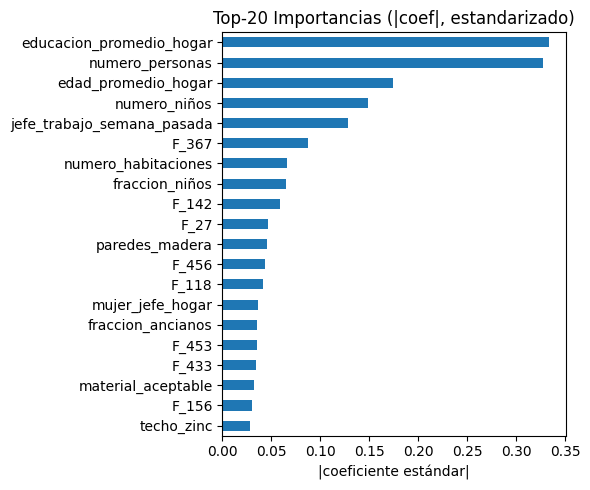

In [ ]:
import matplotlib.pyplot as plt

coeffs = pd.Series(lasso_scaled.coef_, index=X_cols)
top20  = coeffs.abs().nlargest(20).sort_values()

plt.figure(figsize=(6,5))
top20.plot.barh()
plt.title("Top-20 Importancias (|coef|, estandarizado)")
plt.xlabel("|coeficiente estándar|")
plt.tight_layout()
plt.show()


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║           SHAP • Explicar un hogar concreto (Lasso escalado)         ║
# ╚══════════════════════════════════════════════════════════════════════╝
#
# Requisitos:
#   · pipe        : pipeline StandardScaler → LassoCV
#   · df_exp_val  : DataFrame expandido con CASEN + F_0…F_511
#   · vars_RF     : 22 variables
#   · EMB_DIM     : 512
#
# ─────────────────────────────────────────────────────────────────────────
import shap, numpy as np, pandas as pd
import matplotlib.pyplot as plt

# 1.  Seleccionar la fila a explicar
idx =216398                                    # <-- índice del hogar
F_cols = [f"F_{k}" for k in range(EMB_DIM)]
X_cols = vars_RF + F_cols

x_row = df_exp_val.loc[idx, X_cols].astype("float32").values.reshape(1, -1)

# 2.  Obtener versión estandarizada (Scaler dentro del pipeline)
scaler      = pipe.named_steps["standardscaler"]
x_row_std   = scaler.transform(x_row)

# 3.  Crear un pequeño background para el masker (100 filas al azar)
bg_std = scaler.transform(
    df_exp_val.sample(100, random_state=42)[X_cols].astype("float32").values
)

# 4.  LinearExplainer con masker explícito (API > 0.41)
lasso_model = pipe.named_steps["lassocv"]
masker      = shap.maskers.Independent(bg_std)
explainer   = shap.LinearExplainer(lasso_model, masker)

# 5.  SHAP values para la fila
shap_values = explainer(x_row_std)

# 6.  Force plot (matplotlib=True para que aparezca en Colab)
shap.initjs()
shap.plots.force(
    explainer.expected_value,
    shap_values.values[0],
    feature_names=X_cols,
    matplotlib=True
)


# LASSO sin embendings

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║    LASSO (solo variables CASEN) — df_hog_train — sin escalado        ║
# ╚══════════════════════════════════════════════════════════════════════╝
#
# Supone que existen:
#   • df_hog_train : subconjunto de entrenamiento de df_hogares
#   • vars_RF      : lista de 22 variables CASEN
# ════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, warnings
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold

# ----------------------------------------------------------------------
# 1.  Limpieza y matrices
# ----------------------------------------------------------------------
df_ht  = df_hog_train[df_hog_train[Y_COL] > 0].dropna().copy()

X      = df_ht[vars_RF].values                 # sin escalar
y      = np.log(df_ht[Y_COL].values)           # log ingreso
groups = df_ht["comuna"].values                # para CV agrupada

# ----------------------------------------------------------------------
# 2.  LassoCV (α grid 1e-3 … 10)
# ----------------------------------------------------------------------
alphas = np.logspace(-3, 1, 40)
gkf    = GroupKFold(n_splits=10)

lasso_casen = LassoCV(
    alphas      = alphas,
    cv          = gkf.split(X, y, groups=groups),
    n_jobs      = -1,
    random_state= 42,
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lasso_casen.fit(X, y)

# ----------------------------------------------------------------------
# 3.  Resultados
# ----------------------------------------------------------------------
print("\n--- LASSO (df_hog_train, sin escalar) ---")
print(f"α* elegido : {lasso_casen.alpha_:.4g}")
print(f"R² train   : {lasso_casen.score(X, y):.4f}")

print("\nCoeficientes:")
print(pd.Series(lasso_casen.coef_, index=vars_RF))



--- LASSO (df_hog_train, sin escalar) ---
α* elegido : 0.001
R² train   : 0.4331

Coeficientes:
educacion_jefe_hogar          0.003313
hogar_urbano                  0.045968
mujer_jefe_hogar             -0.066953
densidad_hogar               -0.015185
educacion_promedio_hogar      0.099203
jefe_trabajo_semana_pasada    0.286488
material_aceptable            0.097493
material_recuperable         -0.000000
dependencia_hogar             0.045051
numero_personas               0.208155
edad_promedio_hogar           0.011354
fraccion_ancianos             0.000000
numero_ancianos               0.043119
numero_habitaciones           0.063790
fraccion_niños                0.000000
numero_niños                 -0.116453
techo_zinc                   -0.114408
paredes_madera               -0.151539
piso_madera                   0.053383
piso_radier                   0.009011
paredes_ladrillo             -0.096127
techo_paja                   -0.000000
dtype: float64


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║   LASSO (solo variables CASEN) — df_hog_train — ESCALADO + PESOS     ║
# ║                   Validación cruzada GroupKFold (comuna)            ║
# ╚══════════════════════════════════════════════════════════════════════╝

# ════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import warnings, joblib
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

# --------------------------- 0.  Hiper-parámetros ---------------------- #
N_SPLITS     = 10
ALPHAS       = np.logspace(-3, 1, 40)            # 1e-3 … 10
RANDOM_STATE = 42
MODEL_PATH   = Path("models/lasso_casen_scaled.joblib")

# --------------------------- 1.  Limpieza de datos --------------------- #
df_ht = (
    df_hog_train
    .loc[df_hog_train[Y_COL] > 0]                 # ingreso positivo
    .dropna(subset=vars_RF + ["comuna"])          # columnas necesarias
    .copy()
)

X = df_ht[vars_RF].astype("float32").values
y = np.log(df_ht[Y_COL].values)

# pesos (si no existen, todos = 1) (LASSO sin embendings)
w = df_ht["weight"].values if "weight" in df_ht.columns else np.ones_like(y)

groups = df_ht["comuna"].astype(int).values

# --------------------------- 2.  CV y pipeline ------------------------- #
gkf        = GroupKFold(n_splits=N_SPLITS)
cv_splits  = list(gkf.split(X, y, groups=groups))   # lista ⇒ picklable

pipe_norm = make_pipeline(
    StandardScaler(with_mean=False),
    LassoCV(
        alphas       = ALPHAS,
        cv           = cv_splits,
        n_jobs       = -1,
        random_state = RANDOM_STATE,
    ),
)

# --------------------------- 3.  Entrenamiento ------------------------- #
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    pipe_norm.fit(X, y, lassocv__sample_weight=w)

lasso_scaled = pipe_norm.named_steps["lassocv"]

# --------------------------- 4.  Resultados ---------------------------- #
print("\n─── LASSO (CASEN · escalado) ─────────────────────────────────────")
print(f"α* óptimo            : {lasso_scaled.alpha_:.4g}")
print(f"Iteraciones          : {lasso_scaled.n_iter_}")
print(f"R² ponderado (train) : {r2_score(y, pipe_norm.predict(X), sample_weight=w):.4f}")

# Coeficientes re-escalados a la unidad original
scale = pipe_norm.named_steps["standardscaler"].scale_
coef  = lasso_scaled.coef_ / scale
print("\nCoeficientes (desescalados):")
print(pd.Series(coef, index=vars_RF))

# --------------------------- 5.  Guardar modelo ------------------------ #
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipe_norm, MODEL_PATH, compress=3)
print(f"\n✔ Pipeline guardado en → {MODEL_PATH.resolve()}")



─── LASSO (CASEN · escalado) ─────────────────────────────────────
α* óptimo            : 0.001
Iteraciones          : 70
R² ponderado (train) : 0.4342

Coeficientes (desescalados):
educacion_jefe_hogar          0.002981
hogar_urbano                  0.051246
mujer_jefe_hogar             -0.070440
densidad_hogar               -0.021565
educacion_promedio_hogar      0.098703
jefe_trabajo_semana_pasada    0.291144
material_aceptable            0.114144
material_recuperable         -0.092605
dependencia_hogar             0.003234
numero_personas               0.214243
edad_promedio_hogar           0.011367
fraccion_ancianos             0.214349
numero_ancianos               0.014668
numero_habitaciones           0.061252
fraccion_niños                0.239646
numero_niños                 -0.147125
techo_zinc                   -0.115526
paredes_madera               -0.161747
piso_madera                   0.056749
piso_radier                   0.044635
paredes_ladrillo             -0.10643

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║     Histograms de TODAS las variables numéricas en cada DataFrame    ║
# ║          (df_exp_train  y  df_hog_train) usando matplotlib           ║
# ╚══════════════════════════════════════════════════════════════════════╝
#
# • Crea carpetas “hist_exp” y “hist_hog” en el directorio actual.
# • Para cada columna numérica:
#     – Dibuja histograma con 50 bins (ignora NaN).
#     – Guarda la figura como PNG con el nombre de la variable.
# ════════════════════════════════════════════════════════════════════════
import os, math, matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# -----------------------------------------------------------------------
def save_histograms(df: pd.DataFrame, out_dir: str, bins: int = 50):
    """
    Crea un PNG por cada columna numérica de `df` y los guarda en out_dir.
    """
    Path(out_dir).mkdir(exist_ok=True, parents=True)

    num_cols = df.select_dtypes(include="number").columns
    total    = len(num_cols)

    for i, col in enumerate(num_cols, 1):
        data = df[col].dropna()
        if data.empty:          # evita columnas completamente NaN
            continue

        plt.figure()
        plt.hist(data, bins=bins)
        plt.title(f"Histograma · {col}")
        plt.xlabel(col)
        plt.ylabel("Frecuencia")
        plt.tight_layout()

        fname = f"{col}.png".replace("/", "_")
        plt.savefig(os.path.join(out_dir, fname))
        plt.close()

        if i % 50 == 0 or i == total:
            print(f"{i}/{total} histogramas guardados en {out_dir}")

# -----------------------------------------------------------------------
# 1. Histograms para df_exp_train
#    (contiene vars_RF + F_0…F_511 + peso + objetivo)
# -----------------------------------------------------------------------
save_histograms(df_exp_train, out_dir="hist_exp")

# -----------------------------------------------------------------------
# 2. Histograms para df_hog_train
#    (solo variables CASEN)
# -----------------------------------------------------------------------
save_histograms(df_hog_train, out_dir="hist_hog")


50/539 histogramas guardados en hist_exp
100/539 histogramas guardados en hist_exp
150/539 histogramas guardados en hist_exp
200/539 histogramas guardados en hist_exp
250/539 histogramas guardados en hist_exp
300/539 histogramas guardados en hist_exp
350/539 histogramas guardados en hist_exp
400/539 histogramas guardados en hist_exp
450/539 histogramas guardados en hist_exp
500/539 histogramas guardados en hist_exp
539/539 histogramas guardados en hist_exp
31/31 histogramas guardados en hist_hog


# OLS

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║          OLS (solo CASEN) — usando df_hog_train (sin escalado)       ║
# ╚══════════════════════════════════════════════════════════════════════╝
#
# Requiere:
#   • df_hog_train : subconjunto de entrenamiento de hogares
#   • vars_RF      : lista de 22 variables explicativas (CASEN)
#   • ytotcorh     : ingreso per cápita del hogar
# ════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
import statsmodels.api as sm



# 1. Filtrado y preparación
df_ols = df_hog_train[df_hog_train[Y_COL] > 0].dropna().copy()

y = np.log(df_ols[Y_COL].values)     # variable dependiente (log ingreso)
X = sm.add_constant(df_ols[vars_RF]) # predictores + intercepto

# 2. Ajuste OLS
ols_model = sm.OLS(y, X).fit()

# 3. Resumen
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.434
Method:                 Least Squares   F-statistic:                     1510.
Date:                Mon, 01 Sep 2025   Prob (F-statistic):               0.00
Time:                        03:19:21   Log-Likelihood:                -36787.
No. Observations:               43280   AIC:                         7.362e+04
Df Residuals:                   43257   BIC:                         7.382e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

# pruebas

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║        R² en VALIDACIÓN — OLS / Lasso / RF
# ╚══════════════════════════════════════════════════════════════════════╝
from sklearn.metrics import r2_score
import statsmodels.api as sm
import numpy as np

# ----------------------------------------------------------------------
# 0.  Helper: prepara X, y (log) y sample_weight con el mismo filtro
# ----------------------------------------------------------------------
def prep(df, X_cols, weight_col=None):
    """Devuelve X, y_log, w (o None) después de filtrar ytej > 0 y dropna."""
    df2 = df[df[Y_COL] > 0].dropna(subset=X_cols + [Y_COL]).copy()
    X = df2[X_cols].values
    y = np.log(df2[Y_COL].values)
    w = df2[weight_col].values if weight_col else None
    return X, y, w

# ----------------------------------------------------------------------
# 1.  OLS
# ----------------------------------------------------------------------
X_val_ols, y_val_ols, _ = prep(df_hog_val, vars_RF)
X_val_ols = sm.add_constant(X_val_ols)
y_hat_ols = ols_model.predict(X_val_ols)
r2_val_ols = r2_score(y_val_ols, y_hat_ols)
print(f"R² validación (OLS)            : {r2_val_ols:.4f}")

# ----------------------------------------------------------------------
# 2.  Lasso SOLO CASEN
# ----------------------------------------------------------------------
X_val_lc, y_val_lc, _ = prep(df_hog_val, vars_RF)
r2_val_lasso_casen = pipe_norm.score(X_val_lc, y_val_lc)
print(f"R² validación (Lasso CASEN)    : {r2_val_lasso_casen:.4f}")

# ----------------------------------------------------------------------
# 3.  Lasso con EMBEDDINGS
# ----------------------------------------------------------------------
X_cols_exp = vars_RF + [f"F_{k}" for k in range(EMB_DIM)]
X_val_le, y_val_le, w_val_le = prep(df_exp_val, X_cols_exp, weight_col="weight")
y_hat_le = pipe.predict(X_val_le)
r2_val_le = r2_score(y_val_le, y_hat_le, sample_weight=w_val_le)
print(f"R² validación (Lasso + emb)    : {r2_val_le:.4f}")



R² validación (OLS)            : 0.4345
R² validación (Lasso CASEN)    : 0.4341
R² validación (Lasso + emb)    : 0.4768


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║        R² en TEST (out-of-sample) — OLS / Lasso / Lasso+Embeddings   ║
# ╚══════════════════════════════════════════════════════════════════════╝
from sklearn.metrics import r2_score
import statsmodels.api as sm
import numpy as np

# ----------------------------------------------------------------------
# 0.  Helper: prepara X, y (log) y sample_weight con el mismo filtro
# ----------------------------------------------------------------------
def prep(df, X_cols, weight_col=None):
    """Devuelve X, y_log, w (o None) después de filtrar Y_COL>0 y dropna."""
    df2 = df[df[Y_COL] > 0].dropna(subset=X_cols + [Y_COL]).copy()
    X = df2[X_cols].values
    y = np.log(df2[Y_COL].values)
    w = df2[weight_col].values if weight_col else None
    return X, y, w

# ----------------------------------------------------------------------
# 1.  OLS
# ----------------------------------------------------------------------
X_te_ols, y_te_ols, _ = prep(df_hog_test, vars_RF)
X_te_ols = sm.add_constant(X_te_ols)
y_hat_ols = ols_model.predict(X_te_ols)
r2_test_ols = r2_score(y_te_ols, y_hat_ols)
print(f"R² test (OLS)                  : {r2_test_ols:.4f}")

# ----------------------------------------------------------------------
# 2.  Lasso SOLO CASEN
# ----------------------------------------------------------------------
X_te_lc, y_te_lc, _ = prep(df_hog_test, vars_RF)
r2_test_lasso_casen = pipe_norm.score(X_te_lc, y_te_lc)
print(f"R² test (Lasso CASEN)          : {r2_test_lasso_casen:.4f}")

# ----------------------------------------------------------------------
# 3.  Lasso con EMBEDDINGS
# ----------------------------------------------------------------------
X_cols_exp = vars_RF + [f"F_{k}" for k in range(EMB_DIM)]
X_te_le, y_te_le, w_te_le = prep(df_exp_test, X_cols_exp, weight_col="weight")
y_hat_le = pipe.predict(X_te_le)
r2_test_le = r2_score(y_te_le, y_hat_le, sample_weight=w_te_le)
print(f"R² test (Lasso + emb)          : {r2_test_le:.4f}")


R² test (OLS)                  : 0.4317
R² test (Lasso CASEN)          : 0.4318
R² test (Lasso + emb)          : 0.4672


OLS vs Observado (validación)  —  R² validación: 0.4034


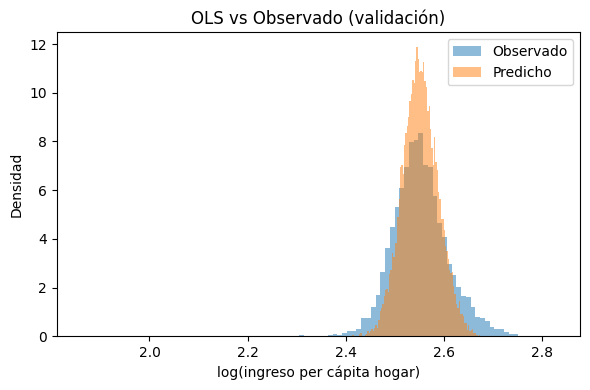

Lasso (CASEN) vs Observado (validación)  —  R² validación: 0.3886


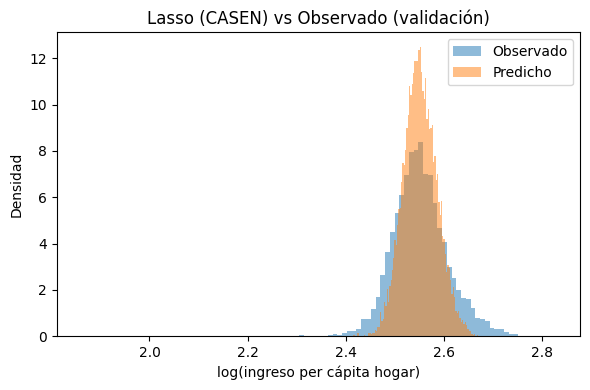

Lasso (CASEN + Embeddings) vs Observado (validación)  —  R² validación: 0.3996


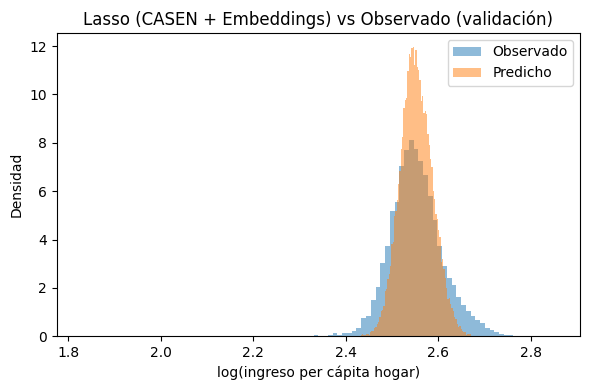

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║   Histogramas Observado vs Predicho (VALID) con filtrado anti-inf    ║
# ║          OLS · Lasso CASEN · Lasso CASEN+Embeddings                  ║
# ╚══════════════════════════════════════════════════════════════════════╝

# ----------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import r2_score

X_cols_exp = vars_RF + [f"F_{k}" for k in range(EMB_DIM)]  # para modelo embeddings

# ─────────────────────────── helper ────────────────────────────────────
def make_histograms(df_val, model, X_cols, title, weight_col=None):
    """
    • df_val      : DataFrame de validación
    • model       : modelo con .predict   (statsmodels o sklearn)
    • X_cols      : lista de columnas predictoras (sin constante)
    • title       : título del gráfico
    • weight_col  : nombre de la columna de pesos o None
    """
    # 1. Filtrar valores >0 y sin NaN en X/y/weight
    filt = df_val[Y_COL] > 0
    filt &= df_val[X_cols].notna().all(axis=1)
    if weight_col:
        filt &= df_val[weight_col].notna()

    df = df_val.loc[filt].copy()

    y   = np.log(df[Y_COL].values)
    X   = df[X_cols].values
    w   = df[weight_col].values if weight_col else None

    # Añadir intercepto si el modelo es statsmodels(OLS)
    if isinstance(model, sm.regression.linear_model.RegressionResultsWrapper):
        X_pred = sm.add_constant(X)
        y_hat  = model.predict(X_pred)
    else:
        y_hat = model.predict(X)

    # 2. R² ponderado / no ponderado
    r2 = r2_score(y, y_hat, sample_weight=w)
    print(f"{title}  —  R² validación: {r2:.4f}")

    # 3. Histograma
    plt.figure(figsize=(6, 4))
    plt.hist(y,      bins=100, density=True, alpha=0.5,
             label="Observado", weights=w)
    plt.hist(y_hat,  bins=100, density=True, alpha=0.5,
             label="Predicho",  weights=w)
    plt.title(title)
    plt.xlabel("log(ingreso per cápita hogar)")
    plt.ylabel("Densidad")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ───────────────────────── 1. OLS ──────────────────────────────────────
make_histograms(
    df_hog_val,
    ols_model,
    vars_RF,
    "OLS vs Observado (validación)"
)

# ───────────────────────── 2. Lasso CASEN ─────────────────────────────
make_histograms(
    df_hog_val,
    lasso_casen,
    vars_RF,
    "Lasso (CASEN) vs Observado (validación)"
)

# ───────────────────────── 3. Lasso + Embeddings ──────────────────────
make_histograms(
    df_exp_val,
    lasso,
    X_cols_exp,
    "Lasso (CASEN + Embeddings) vs Observado (validación)",
    weight_col="weight"
)


OLS vs Observado (validación)  —  R² validación: 0.4087


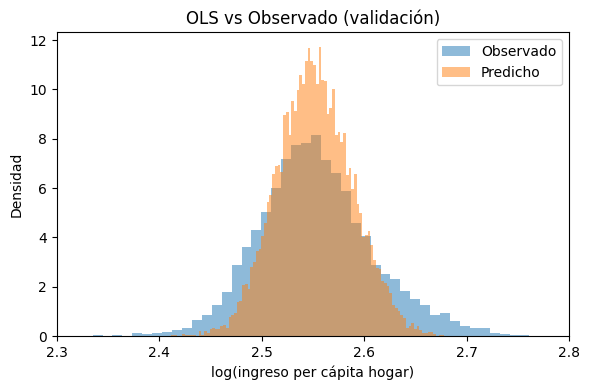

Lasso (CASEN) vs Observado (validación)  —  R² validación: 0.3905


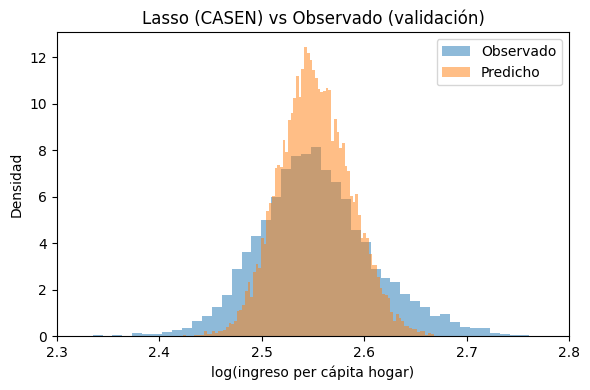

Lasso (CASEN + Embeddings) vs Observado (validación)  —  R² validación: 0.3943


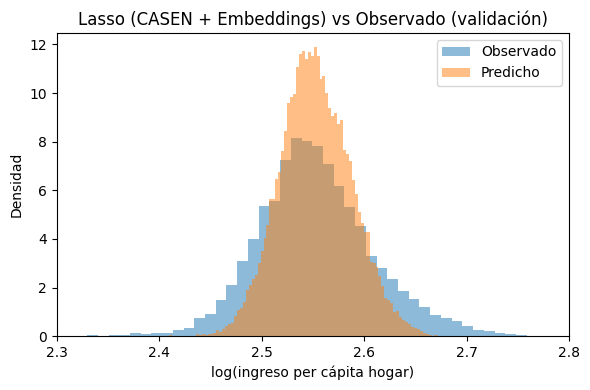

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import r2_score

X_cols_exp = vars_RF + [f"F_{k}" for k in range(EMB_DIM)]  # para modelo embeddings

def make_histograms(df_val, model, X_cols, title, weight_col=None):
    """
    • df_val      : DataFrame de validación
    • model       : modelo con .predict   (statsmodels o sklearn)
    • X_cols      : lista de columnas predictoras (sin constante)
    • title       : título del gráfico
    • weight_col  : nombre de la columna de pesos o None
    """
    # 1. Filtrar valores >0 y sin NaN en X/y/weight
    filt = df_val[Y_COL] > 0
    filt &= df_val[X_cols].notna().all(axis=1)
    if weight_col:
        filt &= df_val[weight_col].notna()

    df = df_val.loc[filt].copy()

    y = np.log(df[Y_COL].values)
    X = df[X_cols].values
    w = df[weight_col].values if weight_col else None

    # Añadir intercepto si el modelo es statsmodels
    if isinstance(model, sm.regression.linear_model.RegressionResultsWrapper):
        Xp = sm.add_constant(X)
        y_hat = model.predict(Xp)
    else:
        y_hat = model.predict(X)

    # 2. R² ponderado / no ponderado
    r2 = r2_score(y, y_hat, sample_weight=w)
    print(f"{title}  —  R² validación: {r2:.4f}")

    # 3. Histograma con eje X fijo
    plt.figure(figsize=(6, 4))
    plt.hist(y,      bins=100, density=True, alpha=0.5,
             label="Observado", weights=w)
    plt.hist(y_hat,  bins=100, density=True, alpha=0.5,
             label="Predicho",  weights=w)
    plt.xlim(2.3, 2.8)                        # <-- eje X fijo
    plt.title(title)
    plt.xlabel("log(ingreso per cápita hogar)")
    plt.ylabel("Densidad")
    plt.legend()
    plt.tight_layout()
    plt.show()


# ───────────────────────── 1. OLS ──────────────────────────────────────
make_histograms(
    df_hog_val,
    ols_model,
    vars_RF,
    "OLS vs Observado (validación)"
)

# ───────────────────────── 2. Lasso CASEN ─────────────────────────────
make_histograms(
    df_hog_val,
    lasso_casen,
    vars_RF,
    "Lasso (CASEN) vs Observado (validación)"
)

# ───────────────────────── 3. Lasso + Embeddings ──────────────────────
make_histograms(
    df_exp_val,
    lasso,
    X_cols_exp,
    "Lasso (CASEN + Embeddings) vs Observado (validación)",
    weight_col="weight"
)
